<a href="https://colab.research.google.com/github/sebastianvettel1212/GrokkingDeepLearning/blob/main/09_Activation_Functions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 9 — Memodelkan Probabilitas dan Nonlinearitas: Fungsi Aktivasi (*Intro to Activation Functions*)

**Buku:** *Grokking Deep Learning* — Andrew W. Trask (Manning, 2019)

Bab ini menjawab: **fungsi apa yang sebaiknya dipasang pada keluaran sebuah layer?** *Hidden layer* yang diberi fungsi nonlinear (Bab 6: ReLU) membuat jaringan mampu menciptakan korelasi; *output layer* yang diberi fungsi yang sesuai membuat jaringan **memodelkan probabilitas**. Kita mempelajari sigmoid, tanh, ReLU, dan ***softmax***, serta cara memasangnya pada *backpropagation*. Kode diambil dari repositori resmi buku, ditambah teori dan eksperimen pendukung (berlabel *Tambahan*).

---

## Daftar Isi
0. Persiapan
1. Apa Itu Fungsi Aktivasi?
2. Fungsi Aktivasi Standar pada *Hidden Layer*
3. Fungsi Aktivasi Standar pada *Output Layer*
4. Masalah Inti: Input Memiliki Kemiripan
5. Perhitungan *Softmax*
6. Memasang Aktivasi: Mengalikan Delta dengan Slope
7. Mengubah Output Menjadi Slope (Turunan)
8. Meningkatkan Jaringan MNIST
9. Perbandingan Terkontrol *(Tambahan)*
10. Tanya-Jawab Konsep dan Latihan
11. Ringkasan Bab

## 0. Persiapan

In [1]:
import os, gzip, pickle, urllib.request, warnings
import numpy as np
warnings.filterwarnings('ignore')

def load_mnist():
    """Memuat MNIST. Mencoba Keras dahulu (seperti di buku); bila tidak tersedia,
    memakai salinan MNIST di GitHub (mnielsen/neural-networks-and-deep-learning)."""
    try:
        from keras.datasets import mnist
        return mnist.load_data()
    except Exception:
        url = ('https://github.com/mnielsen/neural-networks-and-deep-learning/'
               'raw/master/data/mnist.pkl.gz')
        if not os.path.exists('mnist.pkl.gz'):
            urllib.request.urlretrieve(url, 'mnist.pkl.gz')
        with gzip.open('mnist.pkl.gz', 'rb') as f:
            tr, va, te = pickle.load(f, encoding='latin1')
        x_train = np.concatenate([tr[0], va[0]]).reshape(-1, 28, 28) * 255
        y_train = np.concatenate([tr[1], va[1]])
        return (x_train, y_train), (te[0].reshape(-1, 28, 28) * 255, te[1])

In [2]:
import sys, time
import numpy as np
import matplotlib.pyplot as plt

(x_train, y_train), (x_test, y_test) = load_mnist()
print('data latih:', x_train.shape, '| data uji:', x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
data latih: (60000, 28, 28) | data uji: (10000, 28, 28)


---
## 1. Apa Itu Fungsi Aktivasi?

**Fungsi aktivasi** adalah fungsi yang diterapkan pada vektor keluaran sebuah layer (`layer_1 = f(layer_0 · W)`), dilakukan **node demi node** (elemen demi elemen). ReLU yang kita pakai sejak Bab 6 adalah salah satunya (`(x > 0) * x`).

Fungsi aktivasi **yang baik** punya empat sifat:
1. **Kontinu dan terdefinisi untuk semua input:** setiap input menghasilkan tepat satu output, tanpa "loncatan" (fungsi yang meloncat tidak memiliki slope sehingga tidak dapat dipakai *gradient descent*).
2. **Monoton:** selalu naik (atau selalu turun). Fungsi yang naik-turun membuat satu output berasal dari banyak input, sehingga *gradient descent* kebingungan arah.
3. **Nonlinear:** melengkung ("*squiggle*") agar jaringan bisa memodelkan hubungan yang tidak linear dan menciptakan korelasi (dua layer linear = satu layer linear, Bab 3 dan 6). Fungsi nonlinear juga membuat satu node dapat "memilih" kapan ikut berkontribusi.
4. **Efisien dihitung:** fungsi ini dipanggil jutaan kali.

Ilustrasi fungsi yang melanggar tiap sifat dibanding fungsi yang baik:

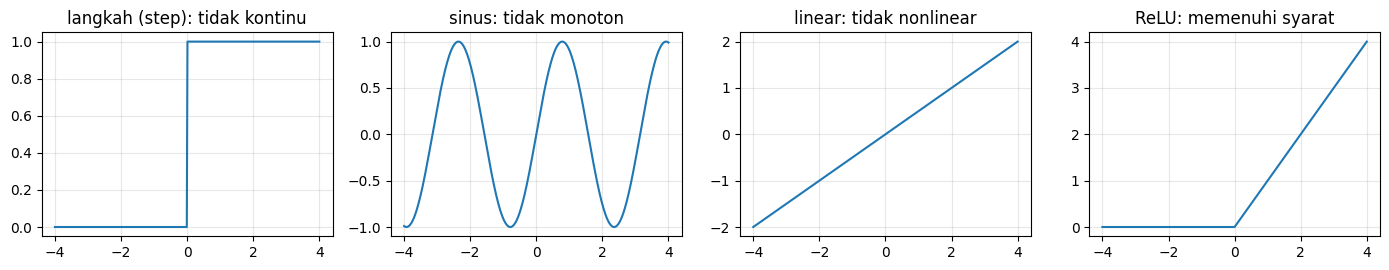

In [3]:
# Tambahan (tidak ada di buku): fungsi yang melanggar syarat vs fungsi yang baik
x = np.linspace(-4, 4, 400)
relu_f = lambda v: (v > 0) * v
fig, ax = plt.subplots(1, 4, figsize=(14, 2.8))
ax[0].plot(x, (x > 0).astype(float));        ax[0].set_title('langkah (step): tidak kontinu')
ax[1].plot(x, np.sin(2 * x));                ax[1].set_title('sinus: tidak monoton')
ax[2].plot(x, 0.5 * x);                      ax[2].set_title('linear: tidak nonlinear')
ax[3].plot(x, relu_f(x));                    ax[3].set_title('ReLU: memenuhi syarat')
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Interpretasi:** fungsi langkah punya loncatan (slope tidak terdefinisi/nol di mana-mana), sinus naik-turun, dan fungsi linear tidak menambah kemampuan jaringan. ReLU kontinu, monoton (tidak menurun), nonlinear, dan sangat murah dihitung.

---
## 2. Fungsi Aktivasi Standar pada *Hidden Layer*

| Fungsi | Rumus | Rentang | Turunan (dari *output* $o$) | Catatan |
|---|---|---|---|---|
| **Sigmoid** | $\dfrac{1}{1+e^{-x}}$ | (0, 1) | $o\,(1-o)$ | Mengubah sinyal menjadi "skala 0 sampai 1" (seperti peluang menyala); tidak pernah negatif |
| **Tanh** | $\dfrac{e^{x}-e^{-x}}{e^{x}+e^{-x}}$ | (−1, 1) | $1-o^2$ | Seperti sigmoid tetapi dapat **negatif**, sehingga node bisa menyatakan **korelasi negatif**; biasanya lebih baik daripada sigmoid pada hidden layer |
| **ReLU** | $\max(0,x)$ | [0, ∞) | $1$ bila $o>0$, selain itu $0$ | Sederhana dan sangat cepat; dasar banyak jaringan modern |

Mengapa tanh sering lebih baik daripada sigmoid di hidden layer? Sigmoid hanya bisa menyatakan "menyala" atau "tidak"; tanh juga dapat menyatakan **"menentang"** (nilai negatif), sehingga jaringan dapat menciptakan **korelasi negatif** antara hidden node dan output.

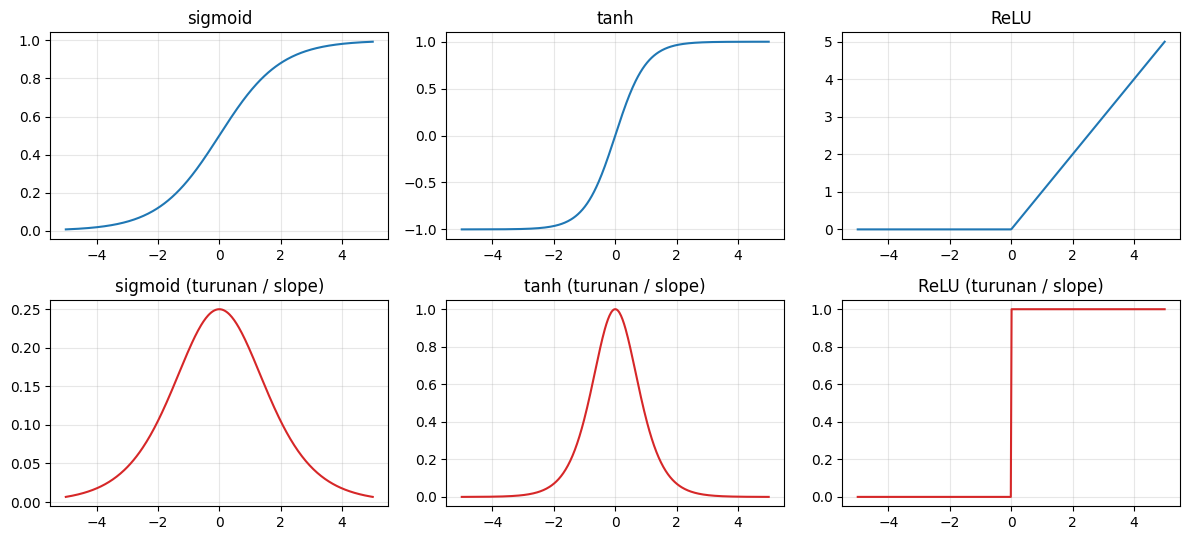

In [4]:
# Tambahan (tidak ada di buku): bentuk dan turunan fungsi aktivasi hidden layer
sigmoid = lambda v: 1 / (1 + np.exp(-v))
tanh_f  = np.tanh
relu_f  = lambda v: (v > 0) * v

d_sigmoid = lambda o: o * (1 - o)          # turunan dihitung dari OUTPUT (bagian 7)
d_tanh    = lambda o: 1 - o ** 2
d_relu    = lambda o: (o > 0) * 1.0

x = np.linspace(-5, 5, 400)
fig, ax = plt.subplots(2, 3, figsize=(12, 5.5))
for k, (nm, f, df) in enumerate([('sigmoid', sigmoid, d_sigmoid), ('tanh', tanh_f, d_tanh), ('ReLU', relu_f, d_relu)]):
    ax[0, k].plot(x, f(x)); ax[0, k].set_title(nm); ax[0, k].grid(alpha=0.3)
    ax[1, k].plot(x, df(f(x)), color='tab:red'); ax[1, k].set_title(nm + ' (turunan / slope)'); ax[1, k].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Interpretasi:** baris bawah menunjukkan **slope** tiap fungsi. Sigmoid dan tanh punya slope kecil di kedua ekor (**jenuh**): input yang sangat besar atau sangat kecil memberi gradien hampir 0 sehingga belajar melambat (*vanishing gradient*). Slope ReLU bernilai 1 untuk aktif dan 0 untuk mati.

---
## 3. Fungsi Aktivasi Standar pada *Output Layer*

Pilihan fungsi aktivasi **output** bergantung pada **apa yang diprediksi**:

1. **Tanpa aktivasi:** untuk prediksi nilai mentah (regresi) atau bila output tidak dibatasi, seperti pada Bab 3–8.
2. **Sigmoid:** untuk **klasifikasi biner** atau beberapa label yang **boleh benar bersamaan** (*multi-label*): tiap output berdiri sendiri sebagai peluang (mis. "gambar ini berisi anjing? berisi kucing?").
3. ***Softmax*:** untuk klasifikasi **satu dari banyak kelas yang saling meniadakan** (mis. angka 0–9): output membentuk **distribusi peluang** (semua positif, jumlah = 1).

> **Aturan praktis:** *"Pilih satu"* → softmax. *"Ya/tidak untuk tiap hal"* → sigmoid. *"Nilai bebas"* → tanpa aktivasi.

---
## 4. Masalah Inti: Input Memiliki Kemiripan

Pada Bab 8, jaringan diberi target *one-hot* dan dilatih dengan ***mean squared error*** pada skor mentah. Kelemahan mendasar: **gambar angka berbeda saling mirip** (mis. 3 dan 8 berbagi banyak piksel; 4 dan 9 berbagi bentuk), tetapi error kuadrat menuntut output kelas lain mendekati **tepat 0** dan output kelas benar mendekati **tepat 1**, terlepas dari seberapa sulit pembedaannya. Jaringan akhirnya dihukum untuk **kemiripan alami** yang tidak bisa dihilangkan, dan terus memaksakan nilai absolut yang tidak penting.

Yang sebenarnya kita butuhkan adalah **peringkat relatif**: kelas benar harus **lebih tinggi** dari yang lain, tanpa harus bernilai tepat 1. ***Softmax*** mewujudkan itu: ia membuat kelas-kelas **bersaing**; menaikkan peluang satu kelas otomatis menurunkan peluang yang lain.

Perbandingan konkret gradien terhadap skor output untuk satu gambar yang **sudah diklasifikasikan benar dengan margin besar**:

In [5]:
# Tambahan (tidak ada di buku): MSE pada skor mentah vs softmax + cross-entropy
def softmax(z):
    e = np.exp(z - z.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)

z = np.array([3.0, 0.5, 0.5])         # skor mentah: kelas 0 jelas unggul
y = np.array([1.0, 0.0, 0.0])         # target: kelas 0

grad_mse = z - y                       # d/dz dari 0.5*(z-y)^2
grad_ce  = softmax(z) - y              # d/dz dari cross-entropy(softmax(z), y)

print('skor mentah         :', z)
print('softmax(z)          :', softmax(z).round(3))
print('gradien MSE         :', grad_mse, ' <- masih mendorong skor kelas 0 TURUN dari 3 menuju 1')
print('gradien softmax+CE  :', grad_ce.round(3), ' <- kecil: prediksi sudah benar & yakin')

skor mentah         : [3.  0.5 0.5]
softmax(z)          : [0.859 0.071 0.071]
gradien MSE         : [2.  0.5 0.5]  <- masih mendorong skor kelas 0 TURUN dari 3 menuju 1
gradien softmax+CE  : [-0.141  0.071  0.071]  <- kecil: prediksi sudah benar & yakin


**Interpretasi:** dengan MSE pada skor mentah, jaringan **dihukum karena skor kelas benar terlalu besar** (3 dianggap meleset dari 1) sehingga terus ditarik turun. Dengan softmax, gradiennya sangat kecil karena kelas benar sudah dominan; jaringan tidak membuang kapasitas untuk memaksakan nilai absolut.

---
## 5. Perhitungan *Softmax*

Untuk skor mentah $z_1,\dots,z_K$:
$$\text{softmax}(z)_i=\frac{e^{z_i}}{\sum_{j}e^{z_j}}$$
Langkah: (1) **eksponensialkan** tiap skor (membuat semuanya positif dan memperbesar selisih), (2) **bagi** dengan jumlah total (sehingga jumlah = 1).

**Sifat penting:** karena penyebut berisi seluruh skor, **menaikkan satu skor menurunkan peluang semua kelas lain**; inilah "persaingan" antarkelas. Eksponensial juga membuat skor terbesar mendapat porsi jauh lebih besar (*winner-takes-most*).

In [6]:
# Perhitungan softmax langkah demi langkah (dengan angka sederhana)
z = np.array([1.0, 2.0, 3.0])
eksp = np.exp(z)
print('skor mentah     :', z)
print('exp(skor)       :', eksp.round(3))
print('jumlah exp      :', eksp.sum().round(3))
print('softmax         :', (eksp / eksp.sum()).round(3), '| jumlah =', (eksp / eksp.sum()).sum().round(3))

# Tambahan: naikkan satu skor -> peluang yang lain turun
for naik in [0, 1, 2, 3]:
    z2 = z.copy(); z2[0] += naik
    print(f'skor kelas-0 +{naik}: softmax =', softmax(z2).round(3))

skor mentah     : [1. 2. 3.]
exp(skor)       : [ 2.718  7.389 20.086]
jumlah exp      : 30.193
softmax         : [0.09  0.245 0.665] | jumlah = 1.0
skor kelas-0 +0: softmax = [0.09  0.245 0.665]
skor kelas-0 +1: softmax = [0.212 0.212 0.576]
skor kelas-0 +2: softmax = [0.422 0.155 0.422]
skor kelas-0 +3: softmax = [0.665 0.09  0.245]


**Interpretasi:** skor terbesar (3) mendapat peluang ≈ 0,665. Ketika skor kelas-0 dinaikkan, peluangnya naik sementara peluang kelas 1 dan 2 **turun**: persaingan antarkelas.

---
## 6. Memasang Aktivasi: Mengalikan Delta dengan Slope

Ketika sebuah layer memakai fungsi aktivasi $f$, *backpropagation* harus memperhitungkannya. Aturan umumnya (sudah kita pakai untuk ReLU di Bab 6):

> `layer_1_delta = (layer_2_delta · W₁₂ᵀ) × f′(layer_1)`

Mengapa dikali **slope** $f'$? Delta menjawab: *"seberapa besar dan ke arah mana saya ingin keluaran node ini berubah"*. Namun yang kita ubah adalah **input node** (hasil *weighted sum*), sebelum fungsi aktivasi. Slope $f'$ menyatakan seberapa **sensitif** keluaran terhadap perubahan input itu: slope besar → perubahan input berdampak besar; slope 0 (node jenuh atau mati) → perubahan input tidak berdampak, sehingga delta diredam menjadi 0.

Pada *output layer*: bila memakai **softmax dengan cross-entropy**, turunan gabungannya menyederhana menjadi $\text{delta}=\text{target}-\text{softmax output}$, sehingga **tidak perlu** dikalikan slope tambahan di output (inilah mengapa kode buku tetap memakai `layer_2_delta = labels - layer_2`).

---
## 7. Mengubah Output Menjadi Slope (Turunan)

Karena saat *backpropagation* kita sudah menyimpan **keluaran** layer (`layer_1`), turunan paling praktis dinyatakan **dalam keluaran itu sendiri**:

| Fungsi | Turunan dalam output $o$ |
|---|---|
| Sigmoid | $o\,(1-o)$ |
| Tanh | $1-o^2$ |
| ReLU | $\mathbb{1}[o>0]$ |

Kita buktikan rumus itu dengan **cek gradien numerik** pada jaringan kecil (tanh di hidden layer, softmax di output): gradien dari *backpropagation* harus sama dengan gradien hasil beda hingga.

In [7]:
# Tambahan (tidak ada di buku): cek gradien numerik untuk backprop dengan tanh + softmax
rng = np.random.RandomState(0)
X = rng.randn(5, 4)                            # 5 contoh, 4 fitur
Y = np.eye(3)[rng.randint(0, 3, 5)]            # target one-hot 3 kelas
W0 = rng.randn(4, 6) * 0.5; W1 = rng.randn(6, 3) * 0.5

def forward(W0, W1):
    l1 = np.tanh(X @ W0); p = softmax(l1 @ W1)
    return l1, p
def loss(W0, W1):
    _, p = forward(W0, W1)
    return -np.sum(Y * np.log(p)) / len(X)     # cross-entropy rata-rata

# gradien analitik (aturan bab ini): delta = (p - Y) di output, lalu dikali slope tanh (1 - o^2)
l1, p = forward(W0, W1)
d2 = (p - Y) / len(X)
d1 = d2 @ W1.T * (1 - l1 ** 2)
g1, g0 = l1.T @ d2, X.T @ d1

# gradien numerik (beda hingga)
def numerik(W):
    g = np.zeros_like(W); h = 1e-6
    for idx in np.ndindex(*W.shape):
        W[idx] += h; lp = loss(W0, W1)
        W[idx] -= 2 * h; lm = loss(W0, W1)
        W[idx] += h
        g[idx] = (lp - lm) / (2 * h)
    return g

print('selisih maksimum gradien W1 (backprop vs numerik):', np.abs(g1 - numerik(W1)).max())
print('selisih maksimum gradien W0 (backprop vs numerik):', np.abs(g0 - numerik(W0)).max())

selisih maksimum gradien W1 (backprop vs numerik): 1.3591213376094868e-10
selisih maksimum gradien W0 (backprop vs numerik): 1.900057333692473e-10


**Interpretasi:** selisih sangat kecil (orde 1e-9 atau lebih kecil), sehingga aturan "delta output $=p-y$, lalu dikali slope $1-o^2$ pada hidden layer" **terbukti benar**. Prinsip yang sama berlaku untuk sigmoid ($o(1-o)$) dan ReLU (indikator).

---
## 8. Meningkatkan Jaringan MNIST

Kita "memasang" semua yang dipelajari: **tanh** pada hidden layer, **softmax** pada output, ditambah *dropout* dan *mini-batch* (Bab 8). Beberapa perubahan teknis dibanding Bab 8: bobot awal lebih kecil (`0.02 * random - 0.01`), `alpha` besar (2) karena delta dibagi `batch_size * layer_2.shape[0]`, dan jumlah iterasi 300. *(Pada kode buku, pengujian dijalankan setiap iterasi tetapi hanya dicetak tiap 10; di sini pengujian dilakukan hanya saat dicetak agar lebih cepat; hasilnya sama.)*

In [8]:
np.random.seed(1)

images, labels = (x_train[0:1000].reshape(1000, 28*28) / 255, y_train[0:1000])

one_hot_labels = np.zeros((len(labels), 10))
for i, l in enumerate(labels):
    one_hot_labels[i][l] = 1
labels = one_hot_labels

test_images = x_test.reshape(len(x_test), 28*28) / 255
test_labels = np.zeros((len(y_test), 10))
for i, l in enumerate(y_test):
    test_labels[i][l] = 1

def tanh(x):
    return np.tanh(x)

def tanh2deriv(output):
    return 1 - (output ** 2)

def softmax(x):
    temp = np.exp(x)
    return temp / np.sum(temp, axis=1, keepdims=True)

alpha, iterations, hidden_size = (2, 300, 100)
pixels_per_image, num_labels = (784, 10)
batch_size = 100

weights_0_1 = 0.02 * np.random.random((pixels_per_image, hidden_size)) - 0.01
weights_1_2 = 0.2 * np.random.random((hidden_size, num_labels)) - 0.1
riwayat9 = []

for j in range(iterations):
    correct_cnt = 0
    for i in range(int(len(images) / batch_size)):
        batch_start, batch_end = ((i * batch_size), ((i + 1) * batch_size))
        layer_0 = images[batch_start:batch_end]
        layer_1 = tanh(np.dot(layer_0, weights_0_1))
        dropout_mask = np.random.randint(2, size=layer_1.shape)
        layer_1 *= dropout_mask * 2
        layer_2 = softmax(np.dot(layer_1, weights_1_2))

        for k in range(batch_size):
            correct_cnt += int(np.argmax(layer_2[k:k+1]) == np.argmax(labels[batch_start+k:batch_start+k+1]))

        layer_2_delta = (labels[batch_start:batch_end] - layer_2) / (batch_size * layer_2.shape[0])
        layer_1_delta = layer_2_delta.dot(weights_1_2.T) * tanh2deriv(layer_1)
        layer_1_delta *= dropout_mask

        weights_1_2 += alpha * layer_1.T.dot(layer_2_delta)
        weights_0_1 += alpha * layer_0.T.dot(layer_1_delta)

    if(j % 10 == 0):
        test_correct_cnt = 0
        for i in range(len(test_images)):
            layer_0 = test_images[i:i+1]
            layer_1 = tanh(np.dot(layer_0, weights_0_1))
            layer_2 = np.dot(layer_1, weights_1_2)
            test_correct_cnt += int(np.argmax(layer_2) == np.argmax(test_labels[i:i+1]))
        riwayat9.append((j, test_correct_cnt / float(len(test_images)), correct_cnt / float(len(images))))
        if j % 50 == 0 or j == iterations - 10:
            sys.stdout.write("\n" + "I:" + str(j) +
                             " Test-Acc:" + str(test_correct_cnt / float(len(test_images))) +
                             " Train-Acc:" + str(correct_cnt / float(len(images))))
print()


I:0 Test-Acc:0.394 Train-Acc:0.156
I:50 Test-Acc:0.7913 Train-Acc:0.819
I:100 Test-Acc:0.8407 Train-Acc:0.883
I:150 Test-Acc:0.8555 Train-Acc:0.914
I:200 Test-Acc:0.8642 Train-Acc:0.926
I:250 Test-Acc:0.8687 Train-Acc:0.937
I:290 Test-Acc:0.8701 Train-Acc:0.94


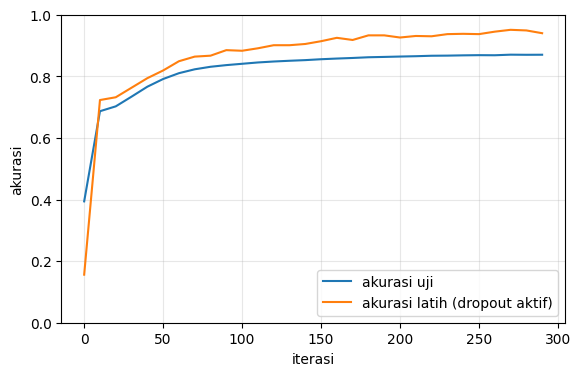

Akurasi uji akhir: 0.8701 | akurasi uji tertinggi: 0.8703


In [9]:
# Tambahan (tidak ada di buku): kurva belajar jaringan tanh + softmax
r = np.array(riwayat9)
plt.figure(figsize=(6.5, 4))
plt.plot(r[:, 0], r[:, 1], label='akurasi uji'); plt.plot(r[:, 0], r[:, 2], label='akurasi latih (dropout aktif)')
plt.xlabel('iterasi'); plt.ylabel('akurasi'); plt.grid(alpha=0.3); plt.legend(); plt.ylim(0.0, 1.0); plt.show()
print(f'Akurasi uji akhir: {r[-1, 1]:.4f} | akurasi uji tertinggi: {r[:, 1].max():.4f}')

**Interpretasi:** jaringan dengan tanh, softmax, dropout, dan mini-batch mencapai akurasi uji ≈ 87,0% setelah 300 iterasi (naik dari ≈ 39% pada iterasi 0 dan ≈ 79% pada iterasi 50), lebih tinggi daripada jaringan ReLU + MSE pada Bab 8 (≈ 71–82% pada kondisi yang mirip). Kurva ujinya naik halus dan tidak menurun seperti jaringan yang overfit. Akurasi latih (dengan dropout aktif) ≈ 94% sehingga selisih latih-uji hanya ≈ 7 poin persentase.

---
## 9. Perbandingan Terkontrol *(Tambahan)*

Kontribusi tiap pilihan dapat dipisahkan: kita latih jaringan yang sama (100 hidden node, dropout, mini-batch 100, 100 iterasi) dengan **kombinasi aktivasi hidden dan output yang berbeda**. Karena kombinasi berbeda membutuhkan `alpha` berbeda, `alpha` dipilih dari beberapa kandidat memakai **data validasi** (gambar latih ke-1000 hingga 2000), dan hanya skor uji untuk `alpha` terpilih yang dilaporkan.

In [10]:
# Tambahan (tidak ada di buku): perbandingan aktivasi hidden dan output
ACT = {'relu': (lambda v: (v >= 0) * v, lambda o: (o >= 0) * 1.0),
       'tanh': (np.tanh, lambda o: 1 - o ** 2),
       'sigmoid': (lambda v: 1 / (1 + np.exp(-np.clip(v, -30, 30))), lambda o: o * (1 - o))}

def softmax_s(z):
    e = np.exp(z - z.max(axis=1, keepdims=True)); return e / e.sum(axis=1, keepdims=True)

def oh(y): return np.eye(10)[y]
Xtr, Ytr = x_train[:1000].reshape(-1, 784) / 255, oh(y_train[:1000])
Xva, Yva = x_train[1000:2000].reshape(-1, 784) / 255, oh(y_train[1000:2000])
Xte, Yte = x_test.reshape(-1, 784) / 255, oh(y_test)

def latih(hact, out, alpha, iters=100, hidden=100, batch=100, seed=1):
    f, df = ACT[hact]; rng = np.random.RandomState(seed)
    w01 = 0.02 * rng.random_sample((784, hidden)) - 0.01
    w12 = 0.2 * rng.random_sample((hidden, 10)) - 0.1
    for _ in range(iters):
        for s in range(0, len(Xtr), batch):
            l0 = Xtr[s:s+batch]; a1 = f(l0 @ w01)
            mask = rng.randint(2, size=a1.shape); l1 = a1 * mask * 2
            z = l1 @ w12; l2 = softmax_s(z) if out == 'softmax' else z
            d2 = (Ytr[s:s+batch] - l2) / batch
            d1 = d2 @ w12.T * df(a1) * mask * 2
            w12 += alpha * l1.T @ d2; w01 += alpha * l0.T @ d1
    acc = lambda A, B: float((np.argmax(f(A @ w01) @ w12, 1) == np.argmax(B, 1)).mean())
    return acc(Xva, Yva), acc(Xte, Yte)

hasil = []
for hact in ['relu', 'tanh', 'sigmoid']:
    for out in ['raw (MSE)', 'softmax']:
        terbaik = (-1, None, None)
        for alpha in [0.003, 0.01, 0.05, 0.2, 1.0, 3.0]:
            with np.errstate(all='ignore'):
                va, te = latih(hact, 'softmax' if out == 'softmax' else 'raw', alpha)
            if np.isfinite(va) and va > terbaik[0]:
                terbaik = (va, alpha, te)
        hasil.append((hact, out, terbaik[1], terbaik[0], terbaik[2]))

print('hidden  | output      | alpha terpilih | akurasi validasi | akurasi uji')
for hact, out, a, va, te in hasil:
    print(f'{hact:7s} | {out:11s} | {a!s:14} | {va:16.3f} | {te:11.4f}')

hidden  | output      | alpha terpilih | akurasi validasi | akurasi uji
relu    | raw (MSE)   | 0.2            |            0.809 |      0.8055
relu    | softmax     | 0.01           |            0.809 |      0.7897
tanh    | raw (MSE)   | 0.01           |            0.820 |      0.8053
tanh    | softmax     | 1.0            |            0.879 |      0.8693
sigmoid | raw (MSE)   | 0.05           |            0.526 |      0.5286
sigmoid | softmax     | 3.0            |            0.889 |      0.8875


**Interpretasi:** *softmax* menaikkan akurasi uji secara jelas pada hidden layer **tanh** (≈ 80,5% → 87,1%) dan **sigmoid** (≈ 52,5% → 88,8%; sigmoid dengan skor mentah dan MSE hampir tidak belajar dalam 100 iterasi). Namun pada hidden layer **ReLU**, softmax justru sedikit lebih rendah (≈ 80,6% → 78,9%) dan hanya stabil pada `alpha` kecil (0,01), kemungkinan karena keluaran ReLU yang tidak terbatas membuat skor sebelum softmax mudah membesar. Jadi manfaat softmax **tidak otomatis** pada semua kombinasi: bergantung pada aktivasi hidden layer dan `alpha`. Sigmoid + softmax terbaik di sini (88,8%), tetapi `alpha` terpilihnya berada di tepi atas grid (3,0), jadi alpha yang lebih besar mungkin masih lebih baik, dan selisih ≈ 1,7 poin dari tanh + softmax berasal dari satu *seed*. Pelajaran utamanya: pilih aktivasi **sesuai tugas**, dan setel `alpha` untuk tiap kombinasi sebelum membandingkannya.

---
## 10. Tanya-Jawab Konsep dan Latihan

**1. Apa empat ciri fungsi aktivasi yang baik?** Kontinu (terdefinisi untuk semua input), monoton, nonlinear, dan efisien dihitung.

**2. Mengapa fungsi aktivasi harus nonlinear?** Tanpa nonlinearitas, tumpukan layer setara satu layer linear; nonlinearitas memungkinkan jaringan menciptakan korelasi baru dan memodelkan hubungan yang lebih rumit.

**3. Kapan memakai sigmoid vs softmax di output?** Sigmoid bila tiap output adalah peluang **independen** (boleh benar bersamaan); softmax bila kelasnya **saling meniadakan** (pilih satu).

**4. Mengapa delta dikalikan slope fungsi aktivasi?** Slope menyatakan seberapa sensitif keluaran terhadap input node; node yang jenuh/mati tidak boleh menerima koreksi besar.

**5. Mengapa softmax membantu pada data yang mirip antarkelas?** Karena menuntut peringkat relatif (kelas benar lebih tinggi) alih-alih nilai absolut tepat 0/1, sehingga kemiripan alami antarkelas tidak lagi dihukum.

**6. Mengapa turunan dinyatakan dalam output (mis. $1-o^2$)?** Output sudah tersimpan dari *forward propagation*, sehingga turunan dapat dihitung tanpa mengulang perhitungan.

### Latihan mandiri
1. Buktikan turunan sigmoid $=o(1-o)$ secara numerik pada beberapa titik.
2. Hitung softmax untuk `[2, 2, 2]` dan `[10, 0, 0]`. Apa yang Anda amati?
3. Mengapa tanh pada hidden layer boleh menghasilkan korelasi negatif, tetapi sigmoid tidak?

In [11]:
# Jawaban latihan mandiri (Tambahan)
v = np.array([-2.0, -0.5, 0.0, 1.0, 3.0]); h = 1e-6
sg = lambda t: 1 / (1 + np.exp(-t))
numerik_turunan = (sg(v + h) - sg(v - h)) / (2 * h)
print('1) turunan numerik     :', numerik_turunan.round(6))
print('   rumus o(1-o)        :', (sg(v) * (1 - sg(v))).round(6))
print('2) softmax([2,2,2])    :', softmax(np.array([[2., 2., 2.]])).round(3), '(seragam)')
print('   softmax([10,0,0])   :', softmax(np.array([[10., 0., 0.]])).round(5), '(hampir seluruh peluang di satu kelas)')
print('3) tanh bernilai negatif untuk input negatif:', np.tanh(-1.0).round(3), '| sigmoid tidak pernah negatif:', sg(-5.0).round(4))

1) turunan numerik     : [0.104994 0.235004 0.25     0.196612 0.045177]
   rumus o(1-o)        : [0.104994 0.235004 0.25     0.196612 0.045177]
2) softmax([2,2,2])    : [[0.333 0.333 0.333]] (seragam)
   softmax([10,0,0])   : [[9.9991e-01 5.0000e-05 5.0000e-05]] (hampir seluruh peluang di satu kelas)
3) tanh bernilai negatif untuk input negatif: -0.762 | sigmoid tidak pernah negatif: 0.0067


---
## 11. Ringkasan Bab

- **Fungsi aktivasi** yang baik: kontinu, monoton, nonlinear, efisien.
- **Hidden layer:** sigmoid, tanh (dapat negatif), ReLU (sederhana, cepat).
- **Output layer:** tanpa aktivasi (nilai bebas), sigmoid (peluang independen), **softmax** (pilih satu kelas).
- Softmax mengatasi **kemiripan antar-input/kelas** dengan menuntut peringkat relatif, bukan nilai absolut.
- *Backpropagation* dengan aktivasi: kalikan delta dengan **slope** fungsi aktivasi (dinyatakan dalam output); untuk softmax + cross-entropy, delta output cukup `target − output`.

### Rangkuman konsep
| Subbab | Konsep | Kode |
|---|---|---|
| Sifat aktivasi | Kontinu, monoton, nonlinear | Grafik pelanggar syarat |
| Hidden layer | Sigmoid, tanh, ReLU | `tanh2deriv`, `d_sigmoid` |
| Output layer | Sigmoid / softmax | `softmax` |
| Softmax | exp lalu normalisasi, persaingan kelas | `np.exp(x) / sum` |
| Delta × slope | Aturan backprop dengan aktivasi | `layer_1_delta = ... * tanh2deriv(layer_1)` |
| MNIST upgrade | tanh + softmax + dropout + batch | `alpha = 2`, `batch_size = 100` |